# Portafolio de Estadística: Prueba F para Comparación de Dos Varianzas
**Enlace al Dataset umesc:** [https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html]
**Dataset de trabajo:** `df_limpio.csv`
**Enlace al Dataset Conapesca:** [https://www.gob.mx/conapesca/documentos/anuario-estadistico-de-acuacultura-y-pesca]
**Dataset de trabajo:** `conapesca_historico_2015_2025_LIMPIO.csv`

<div align="center">
  <a href="https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html">
    <img src="https://img.shields.io/badge/-🗄️_Ir_a_la_Base_de_Datos_umesc-238636?style=for-the-badge" alt="Botón Base de Datos" />
  </a>
</div>

<div align="center">
  <a href="https://www.gob.mx/conapesca/documentos/anuario-estadistico-de-acuacultura-y-pesca">
    <img src="https://img.shields.io/badge/-🗄️_Ir_a_la_Base_de_Datos_Conapesca-238636?style=for-the-badge" alt="Botón Base de Datos" />
  </a>
</div>

<div align="center">
  <a href="https://axiscrazy.github.io/Probabilidad-y-estadistica-2/index.html">
    <img src="https://img.shields.io/badge/-⬅️_Regresar_a_la_página_web-007ACC?style=for-the-badge" alt="Botón Regresar" />
  </a>
</div>

En este portafolio realizaremos una prueba de hipótesis para comparar las varianzas de dos muestras, siguiendo la metodología de la Prueba F (bilateral).

### 1. Definición de Hipótesis y Parámetros de la Prueba
- **Hipótesis Nula ($H_0$)**: Las varianzas poblacionales son iguales ($\sigma_1^2 = \sigma_2^2$).
- **Hipótesis Alternativa ($H_1$)**: Las varianzas poblacionales son diferentes ($\sigma_1^2 \neq \sigma_2^2$).
- **Nivel de Significancia ($\alpha$)**: 0.05 (prueba bilateral).

In [4]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt

# Cargar el dataset
try:
    df = pd.read_csv('df_limpio.csv')
    especies = df['fishcode'].unique()
    muestra1 = df[df['fishcode'] == especies[0]]['weight'].dropna()
    muestra2 = df[df['fishcode'] == especies[1]]['weight'].dropna()
    
    if len(muestra1) > 40: muestra1 = muestra1.sample(n=40, random_state=42)
    if len(muestra2) > 40: muestra2 = muestra2.sample(n=40, random_state=10)
except:
    np.random.seed(42)
    muestra1 = pd.Series(np.random.normal(700, 150, 40))
    muestra2 = pd.Series(np.random.normal(500, 200, 40))

# 1. Tamaños de muestra y Grados de libertad
n1, n2 = len(muestra1), len(muestra2)
gl1, gl2 = n1 - 1, n2 - 1

# 2. Varianzas de cada muestra
var1 = np.var(muestra1, ddof=1)
var2 = np.var(muestra2, ddof=1)

print("--- Parámetros Iniciales de las Muestras ---")
print(f"Muestra 1: Tamaño (n) = {n1}, Varianza = {var1:.4f}, Grados de libertad = {gl1}")
print(f"Muestra 2: Tamaño (n) = {n2}, Varianza = {var2:.4f}, Grados de libertad = {gl2}")

--- Parámetros Iniciales de las Muestras ---
Muestra 1: Tamaño (n) = 40, Varianza = 103265.7686, Grados de libertad = 39
Muestra 2: Tamaño (n) = 40, Varianza = 2467.0199, Grados de libertad = 39


In [5]:
# Asegurar que s1^2 > s2^2 para la fórmula del estadístico F de Fisher (F_p = s_mayor^2 / s_menor^2)
if var1 < var2:
    var1, var2 = var2, var1
    gl1, gl2 = gl2, gl1
    print("\nNota: Se han invertido las muestras para que el numerador sea la varianza mayor (s_mayor^2 / s_menor^2).\n")

# 3. Estadístico Fisher (F_p)
F_p = var1 / var2

# 4. Valores Críticos (Cola bilateral)
alpha = 0.05
F_inf = st.f.ppf(alpha / 2, gl1, gl2)
F_sup = st.f.ppf(1 - alpha / 2, gl1, gl2)

# 5. p-value (dos colas)
p_value = 2 * min(st.f.cdf(F_p, gl1, gl2), 1 - st.f.cdf(F_p, gl1, gl2))

print(f"--- Resultados de la Prueba F ---")
print(f"Estadístico de prueba F_p: {F_p:.4f}")
print(f"Nivel de significancia (alpha): {alpha}")
print(f"Valor crítico inferior (F_inf): {F_inf:.4f}")
print(f"Valor crítico superior (F_sup): {F_sup:.4f}")
print(f"p-value: {p_value:.4e}")

--- Resultados de la Prueba F ---
Estadístico de prueba F_p: 41.8585
Nivel de significancia (alpha): 0.05
Valor crítico inferior (F_inf): 0.5289
Valor crítico superior (F_sup): 1.8907
p-value: 0.0000e+00


In [6]:
# 6. Decisión, Interpretación y Análisis de Errores Posibles
if F_p < F_inf or F_p > F_sup:
    decision = "Rechazar H0"
    interpretacion = "Hay evidencia estadística suficiente para afirmar que las varianzas poblacionales son significativamente diferentes."
    error = "Error Tipo I (Falso Positivo)"
    significado_error = "Rechazar la hipótesis nula cuando en realidad es verdadera."
    interpretacion_error = "Afirmar que las varianzas son diferentes, cuando en la realidad (población) las varianzas son iguales."
else:
    decision = "No rechazar H0 (Se asume igualdad)"
    interpretacion = "No hay evidencia estadística suficiente para afirmar que las varianzas son diferentes. Se asume igualdad de varianzas poblacionales."
    error = "Error Tipo II (Falso Negativo)"
    significado_error = "No rechazar la hipótesis nula cuando en realidad es falsa."
    interpretacion_error = "Afirmar que las varianzas son iguales, cuando en la realidad (población) existe una diferencia significativa entre ellas."

print(f"--- Conclusión y Decisión ---")
print(f"Decisión: {decision}")
print(f"Interpretación: {interpretacion}\n")
print(f"--- Análisis del Error que se puede cometer ---")
print(f"Tipo de Error: {error}")
print(f"Significado estadístico: {significado_error}")
print(f"Interpretación del error: {interpretacion_error}")

--- Conclusión y Decisión ---
Decisión: Rechazar H0
Interpretación: Hay evidencia estadística suficiente para afirmar que las varianzas poblacionales son significativamente diferentes.

--- Análisis del Error que se puede cometer ---
Tipo de Error: Error Tipo I (Falso Positivo)
Significado estadístico: Rechazar la hipótesis nula cuando en realidad es verdadera.
Interpretación del error: Afirmar que las varianzas son diferentes, cuando en la realidad (población) las varianzas son iguales.


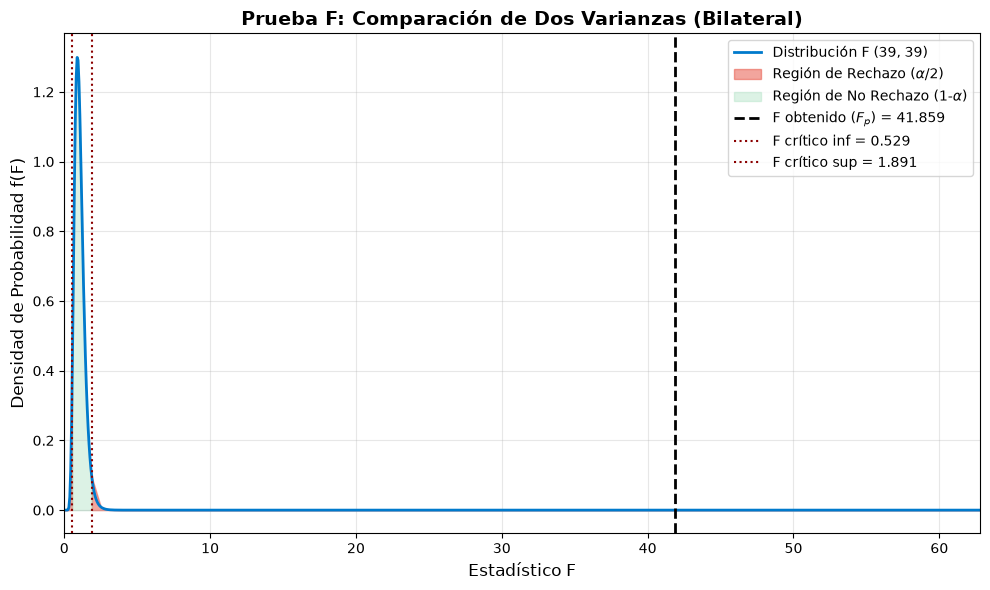

In [7]:
# 7. Gráfica de Distribución F y Regiones de Rechazo
x = np.linspace(0, max(F_sup * 1.5, F_p * 1.5, 3), 1000)
y = st.f.pdf(x, gl1, gl2)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Distribución F ({gl1}, {gl2})', color='#007ACC', linewidth=2)

# Corrección: Uso de raw strings (r'') para que matplotlib parsee LaTeX correctamente y evite el error de la barra espaciadora
x_rej_inf = np.linspace(0, F_inf, 100)
plt.fill_between(x_rej_inf, st.f.pdf(x_rej_inf, gl1, gl2), color='#E74C3C', alpha=0.5, label=r'Región de Rechazo ($\alpha/2$)')

x_rej_sup = np.linspace(F_sup, max(x), 100)
plt.fill_between(x_rej_sup, st.f.pdf(x_rej_sup, gl1, gl2), color='#E74C3C', alpha=0.5)

x_acc = np.linspace(F_inf, F_sup, 500)
plt.fill_between(x_acc, st.f.pdf(x_acc, gl1, gl2), color='#A9DFBF', alpha=0.4, label=r'Región de No Rechazo (1-$\alpha$)')

plt.axvline(F_p, color='black', linestyle='--', linewidth=2, label=f'F obtenido ($F_p$) = {F_p:.3f}')
plt.axvline(F_inf, color='darkred', linestyle=':', linewidth=1.5, label=f'F crítico inf = {F_inf:.3f}')
plt.axvline(F_sup, color='darkred', linestyle=':', linewidth=1.5, label=f'F crítico sup = {F_sup:.3f}')

plt.title("Prueba F: Comparación de Dos Varianzas (Bilateral)", fontsize=14, fontweight='bold')
plt.xlabel("Estadístico F", fontsize=12)
plt.ylabel("Densidad de Probabilidad f(F)", fontsize=12)
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.xlim(0, max(F_sup * 1.5, F_p * 1.5, 3))
plt.tight_layout()
plt.savefig('grafica_distribucion_F.png', dpi=300, bbox_inches='tight')
plt.show()